# Классификация по таблице: пассажиры Titanic
По сведениям о пассажире и его билете попробуем
предсказать, выжил ли он. Известные исходы есть в столбце `survived`:
`0` — не выжил, `1` — выжил. Это два класса, а не числовая величина.

Сравним k ближайших соседей, дерево решений и логистическую регрессию.
Перед обучением придётся обработать пропуски и текстовые категории.
Все модели проверим на одних и тех же отложенных строках.

Запускайте ячейки сверху вниз. Импорты, имена переменных и часть служебного
кода уже есть. В заданиях заменяйте `...` своим кодом. Пока заготовка
не заполнена, связанные с ней ячейки не выполняются.

CSV лежит в папке `data` рядом с блокнотами. В нём 1309 пассажиров.
Интернет во время работы не нужен. Нужны Python, Jupyter, NumPy,
pandas, Matplotlib и scikit-learn версии 1.2 или новее.


## 1. Подготовка

Запустите готовую ячейку. `RANDOM_STATE` фиксирует случайное разделение,
`TEST_SIZE` задаёт долю строк для проверки. Списки столбцов сохраняем
до конца основной работы, чтобы модели получали одинаковые признаки.

Чем вопрос «выжил ли пассажир?» отличается от поиска похожих групп?
Что известно при обучении классификатора?


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
TEST_SIZE = 0.2
NUMERIC_FEATURES = ['age', 'fare', 'sibsp', 'parch']
CATEGORICAL_FEATURES = ['pclass', 'sex', 'embarked']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
CLASS_IDS = [0, 1]
CLASS_NAMES = ['Не выжил', 'Выжил']

DATA_PATH = Path('data/titanic.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('Классификация_90_минут/data/titanic.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Откройте блокнот из папки с data/titanic.csv.')

plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = False


Ответ: при кластеризации правильных групп нет. Алгоритм сам собирает похожие точки, а что эти группы значат, мы решаем потом. Здесь для каждого пассажира из обучения ответ известен заранее, это столбец `survived`. Классификатор учится на парах «признаки пассажира и его исход», а потом предсказывает исход для строк, которых не видел. Это обучение с учителем.

При обучении известны признаки учебных пассажиров и их настоящие исходы. Исходы тестовых пассажиров модели не показывают, по ним её проверяют в конце.

## 2. Строки, столбцы и ответ

Одна строка — один пассажир. Загрузите готовый CSV и посмотрите несколько
записей. Это полная версия Titanic из OpenML, а не выборка на 891 строку,
которую часто используют в соревнованиях.

| Столбец | Что означает |
|---|---|
| `age` | Возраст в годах; у некоторых пассажиров неизвестен |
| `fare` | Стоимость проезда в фунтах; значение относится к записи билета |
| `sibsp` | Число братьев, сестёр и супругов на борту |
| `parch` | Число родителей и детей на борту |
| `pclass` | Класс билета: 1, 2 или 3; будем считать его категорией |
| `sex` | Пол, записанный в наборе |
| `embarked` | Порт посадки: C — Шербур, Q — Куинстаун, S — Саутгемптон |
| `survived` | Известный исход: 0 или 1 |

Остальные столбцы в основной работе не используем.


In [2]:
df = pd.read_csv(DATA_PATH)
print('Размер исходной таблицы:', df.shape)
print('Все столбцы:', list(df.columns))
display(df[FEATURES + ['survived']].head())


Размер исходной таблицы: (1309, 14)
Все столбцы: ['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']


,age,fare,sibsp,parch,pclass,sex,embarked,survived
0,29.0000,211.3375,0,0,1,female,S,1
1,0.9167,151.5500,1,2,1,male,S,1
2,2.0000,151.5500,1,2,1,female,S,0
3,30.0000,151.5500,1,2,1,male,S,0
4,25.0000,151.5500,1,2,1,female,S,0


Посчитайте пропуски в выбранных столбцах и число пассажиров каждого класса.
Постройте простую столбчатую диаграмму классов. Их количества равны?

Проверьте повторение **полных строк исходного CSV**. Совпадение семи
выбранных признаков ещё не означает дубликат: у разных пассажиров могут
быть одинаковые возраст, билет и состав семьи. Такие строки не удаляем.


,Пропусков
age,263
fare,1
sibsp,0
parch,0
pclass,0
sex,0
embarked,2
survived,0


,Пассажиров
survived,
0,809
1,500


Повторяющихся полных строк: 0


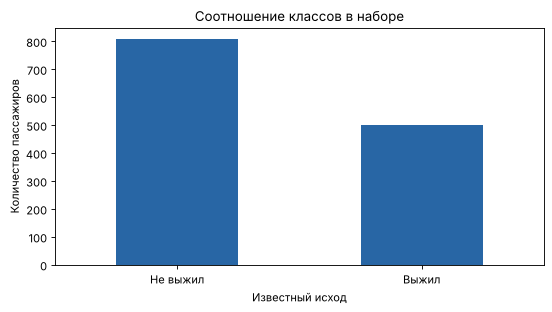

In [3]:
missing_counts = df[FEATURES + ['survived']].isna().sum()  # число пропусков в FEATURES и survived
class_counts = df['survived'].value_counts().sort_index()  # число строк каждого класса, порядок 0, 1
duplicate_count = int(df.duplicated().sum())  # повторения полных строк df
display(missing_counts.rename('Пропусков').to_frame())
display(class_counts.rename('Пассажиров').to_frame())
print('Повторяющихся полных строк:', duplicate_count)

class_counts.plot.bar(color='#2866a5')
plt.xticks([0, 1], CLASS_NAMES, rotation=0)
plt.xlabel('Известный исход')
plt.ylabel('Количество пассажиров')
plt.title('Соотношение классов в наборе')
plt.tight_layout()
plt.show()


Ответ: пропуски есть в трёх столбцах. Возраст неизвестен у 263 пассажиров (примерно у каждого пятого), стоимость проезда у одного, порт посадки у двух. В остальных признаках и в `survived` пропусков нет.

Классы не равны: 809 пассажиров не выжили, 500 выжили, это около 62% и 38%.

Полных повторяющихся строк в CSV нет. Если сравнивать только семь признаков и `survived`, совпадающих строк 195, но это разные люди с одинаковыми значениями, поэтому их не удаляем.

Создайте `X` из семи столбцов списка `FEATURES`, а `y` — из `survived`.
В `X` должны остаться исходные значения, включая пропуски.

`survived` нельзя включать в признаки. `boat` и `body` тоже исключаем:
сведения о спасательной шлюпке и обнаружении тела относятся к событиям
после катастрофы. Модель, которая знает эти сведения, получает подсказку
об исходе, недоступную до события. Это **утечка ответа**.

Имя, номер билета, каюту и место назначения оставим за рамками пары.
Их обработка требует отдельных решений. Список признаков уже выбран.


In [4]:
X = df[FEATURES].copy()  # копия df с признаками из FEATURES
y = df['survived'].copy().astype(int)  # копия survived, привести к int
assert 'survived' not in X.columns
assert not {'boat', 'body'} & set(X.columns)
assert X.index.equals(y.index)
print('Форма X:', X.shape, 'Форма y:', y.shape)
display(X.dtypes.rename('Тип столбца').to_frame())


Форма X: (1309, 7) Форма y: (1309,)


,Тип столбца
age,float64
fare,float64
sibsp,int64
parch,int64
pclass,int64
sex,str
embarked,str


## 3. Отделяем проверку и задаём ориентир

Оставьте 80% строк для обучения и 20% для проверки. Признаки и ответы
делим одновременно. `stratify=y` примерно сохраняет доли классов.

Перед разделением не заполняйте пропуски средним или медианой всего
набора. Эти значения надо вычислять по учебной части. Тест используется
для проверки уже обученной модели.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y,
)
print('Обучение:', X_train.shape, 'Проверка:', X_test.shape)
assert X_train.index.intersection(X_test.index).empty
display(pd.DataFrame({
    'Обучение': y_train.value_counts().sort_index(),
    'Проверка': y_test.value_counts().sort_index(),
}))


Обучение: (1047, 7) Проверка: (262, 7)


,Обучение,Проверка
survived,,
0,647,162
1,400,100


Простой ориентир уже готов: `DummyClassifier` всем пассажирам назначает
самый частый класс учебной части. Признаки он не использует, поэтому
здесь может работать с исходной таблицей.

**Accuracy** — доля правильных ответов. Например, 80 верных ответов
из 100 дают 0,8. Может ли модель получить больше 50%, вообще не глядя
на возраст или билет? Диаграмма классов поможет ответить.


In [6]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
print(f'Простой ориентир: accuracy={accuracy_score(y_test, y_pred_baseline):.3f}')


Простой ориентир: accuracy=0.618


Ответ: да, может. Ориентир всем пассажирам отвечает «не выжил» и получает на тесте accuracy 0.618. В тесте 162 погибших из 262, и все они «угаданы» только потому, что этот класс встречается чаще. Поэтому 62% это нижняя планка. Модель, которая смотрит на признаки, должна давать заметно больше, иначе признаки ей не помогают.

## 4. Готовим таблицу для моделей

У чисел и категорий разная подготовка.

- Числа: `SimpleImputer` заполнит пропуски **медианой учебного столбца**
  (`strategy='median'`). Затем `StandardScaler` приведёт столбцы к
  сопоставимому масштабу: возраст и стоимость проезда имеют разные единицы.
- Категории: другой `SimpleImputer` подставит самое частое учебное значение
  (`strategy='most_frequent'`). `OneHotEncoder` создаст отдельные столбцы
  для категорий, например `sex_female` и `sex_male`.

Допишите два преобразователя. `ColumnTransformer` соединит их результаты.
`handle_unknown='ignore'` позволяет обработать категорию, которой не было
при обучении: в её группе индикаторов будут нули. Это защита от ошибки
программы, а не гарантия хорошего предсказания.

`Pipeline` объединит подготовку с моделью. При `fit` значения для замены,
масштаб и набор категорий будут найдены по `X_train`. При `predict`
тест пройдёт через уже найденные преобразования.


In [7]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # SimpleImputer: замена медианой
    ('scaler', StandardScaler()),
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # SimpleImputer: самое частое значение
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, NUMERIC_FEATURES),
    ('cat', categorical_transformer, CATEGORICAL_FEATURES),
], remainder='drop')


Посмотрим, во что превращается таблица. Ячейка готова: она обучает копию
преобразователя только на `X_train` и показывает первые пять результатов.
`clone` создаёт отдельный экземпляр, чтобы демонстрация не меняла объект,
который затем передадим моделям.

Найдите столбцы возраста и категорий. Почему столбцов стало больше семи?
Почему преобразованный возраст может быть отрицательным? Это значение
ниже среднего учебного возраста, а не отрицательный возраст пассажира.


In [8]:
preview_preprocessor = clone(preprocessor)
prepared_preview = preview_preprocessor.fit_transform(X_train)
prepared_feature_names = preview_preprocessor.get_feature_names_out()
print('До подготовки:', X_train.shape, 'После:', prepared_preview.shape)
print('Пропусков после подготовки:', np.isnan(prepared_preview).sum())
display(pd.DataFrame(prepared_preview[:5],
                     columns=prepared_feature_names).round(2))


До подготовки: (1047, 7) После: (1047, 12)
Пропусков после подготовки: 0


,num__age,num__fare,num__sibsp,num__parch,cat__pclass_1,cat__pclass_2,cat__pclass_3,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S
0,-0.10,-0.50,-0.48,-0.45,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,-0.41,-0.09,0.51,-0.45,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-1.42,-0.02,3.48,1.87,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
3,-0.33,-0.51,-0.48,-0.45,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
4,-1.03,-0.50,-0.48,-0.45,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


Ответ: было 7 столбцов, стало 12. Четыре числовых признака так и остались по одному столбцу: `num__age`, `num__fare`, `num__sibsp`, `num__parch`. Каждая категория превратилась в несколько индикаторов. Класс билета дал три столбца (`cat__pclass_1`, `cat__pclass_2`, `cat__pclass_3`), пол два, порт посадки три: 4 + 3 + 2 + 3 = 12. В каждой группе индикаторов у пассажира одна единица, остальные нули.

Возраст после `StandardScaler` показывает, на сколько стандартных отклонений пассажир моложе или старше среднего по учебной части. Там средний возраст после заполнения около 29.3 года, отклонение около 12.9. У всех, кто моложе среднего, число отрицательное. В третьей строке пассажирке 11 лет, получилось -1.42. В первой строке возраст был пропущен, его заменили медианой учебной части (28 лет), и вышло -0.10. Пропусков после подготовки не осталось.

## 5. k ближайших соседей

Метод находит пассажиров с похожими подготовленными признаками и выбирает
самый частый исход среди пяти соседей. `n_neighbors=5` означает пять
учебных объектов для голосования, а не пять классов.

Pipeline уже задан. Обучите `knn` на учебной части, затем сохраните
предсказания для `X_test` в `y_pred_knn`. В модель передаём исходную таблицу:
подготовку выполняет первый шаг Pipeline.


In [9]:
knn = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', KNeighborsClassifier(n_neighbors=5)),
])
knn.fit(X_train, y_train)  # fit на X_train и y_train
y_pred_knn = knn.predict(X_test)  # predict для X_test
print(f'KNN: accuracy={accuracy_score(y_test, y_pred_knn):.3f}')


KNN: accuracy=0.794


## 6. Дерево решений

Дерево задаёт вопросы про отдельные признаки: «возраст меньше порога?»,
«эта категория равна 1?» Ответ направляет строку по одной из веток.

Ограничим глубину четырьмя уровнями разделения, а число учебных пассажиров
в листе — десятью. Это заранее выбранные настройки основной работы.
Для дерева оставим заполнение пропусков и кодирование категорий, но
отключим масштабирование: так возраст и стоимость на рисунке останутся
в исходных единицах. `passthrough` пропускает данные без этого шага.

Допишите обучение и предсказание. Тест остаётся тем же.


In [10]:
preprocessor_tree = clone(preprocessor)
preprocessor_tree.set_params(num__scaler='passthrough')
tree = Pipeline([
    ('prep', preprocessor_tree),
    ('model', DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                     random_state=RANDOM_STATE)),
])
tree.fit(X_train, y_train)  # обучить tree
y_pred_tree = tree.predict(X_test)  # предсказания для X_test
print(f'Дерево: accuracy={accuracy_score(y_test, y_pred_tree):.3f}')


Дерево: accuracy=0.836


Рисунок первых уровней готов. Если условие верно, идём влево.
У индикатора категории порог 0,5 отделяет значения 0 и 1.

`samples` — число учебных пассажиров в узле, `value` — их количество
по классам в порядке 0, 1, `class` — самый частый исход в узле.
Многоточие в нижней ветви означает, что продолжение дерева скрыто.
Найдите первое условие и объясните два перехода по веткам.


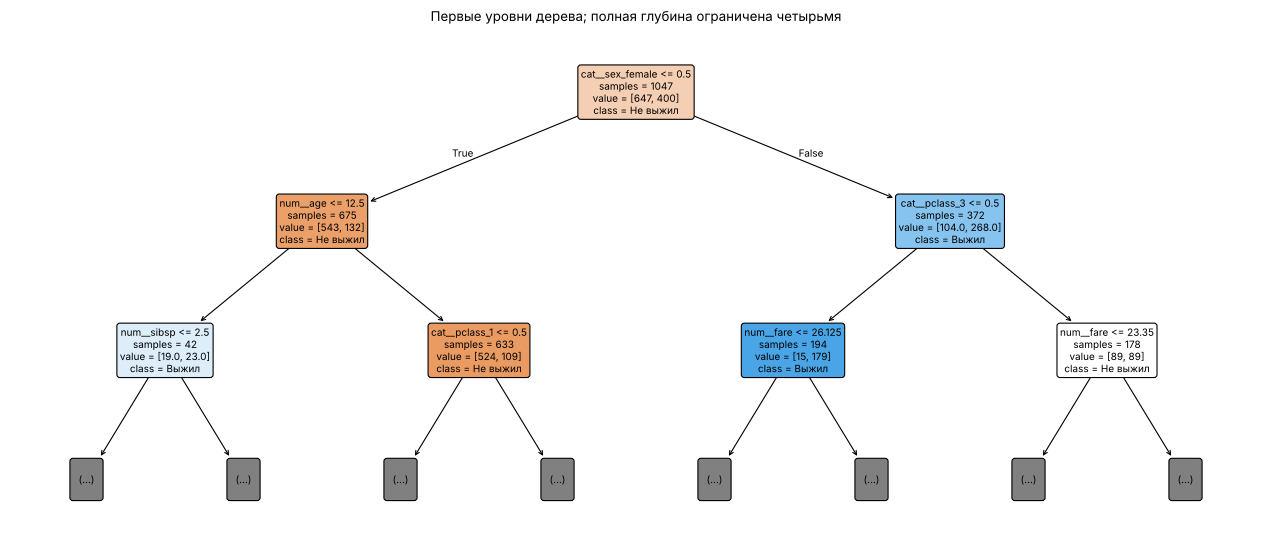

In [11]:
tree_feature_names = tree.named_steps['prep'].get_feature_names_out()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree.named_steps['model'], max_depth=2,
          feature_names=tree_feature_names, class_names=CLASS_NAMES,
          filled=True, impurity=False, rounded=True, fontsize=9, ax=ax)
ax.set_title('Первые уровни дерева; полная глубина ограничена четырьмя')
plt.tight_layout()
plt.show()


Ответ: первое условие `cat__sex_female <= 0.5`. Индикатор равен 0 у мужчин и 1 у женщин, так что вопрос по сути «это мужчина?». В корне 1047 учебных пассажиров, 647 не выжили и 400 выжили.

Если условие верно (мужчина), идём влево. Там 675 пассажиров, 543 не выжили и 132 выжили, поэтому узел помечен «Не выжил». Следующий вопрос в этой ветке про возраст: `num__age <= 12.5`. Среди мальчиков до 12.5 лет (42 человека) выживших уже больше, 23 против 19.

Если условие неверно (женщина), идём вправо. Там 372 пассажирки, 104 не выжили и 268 выжили, узел помечен «Выжил». Дальше дерево спрашивает, не третий ли класс (`cat__pclass_3 <= 0.5`). У женщин первого и второго класса выжили 179 из 194, а в третьем классе ровно половина, 89 из 178.

## 7. Логистическая регрессия

Несмотря на название, `LogisticRegression` решает задачу классификации.
Она сочетает подготовленные признаки и оценивает вероятности двух исходов.
Итоговый класс имеет наибольшую оценку вероятности.

Обучите готовый Pipeline и получите `y_pred_logreg`. Здесь снова есть
масштабирование чисел. `max_iter=1000` ограничивает число шагов обучения.


In [12]:
logreg = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)  # fit
y_pred_logreg = logreg.predict(X_test)  # predict
print(f'Логистическая регрессия: accuracy={accuracy_score(y_test, y_pred_logreg):.3f}')


Логистическая регрессия: accuracy=0.805


## 8. Проверка качества и ошибок

Составьте таблицу для простого ориентира и трёх моделей.
Accuracy на обучении и тесте помогает увидеть разницу между знакомыми
и отложенными строками. Большой разрыв — повод проверить переобучение.

Для следующих метрик считаем положительным классом **1 — «выжил»**:

- **Precision:** какая доля пассажиров с предсказанием «выжил» действительно выжила.
- **Recall:** какую долю всех выживших модель нашла.
- **F1:** одна оценка, учитывающая precision и recall.

Если модель вообще не предсказывает класс 1, precision не определена.
В таблице договоримся показывать 0: для этого используется `zero_division=0`.
Сравните accuracy простого правила с его recall. Почему одной accuracy мало?


In [13]:
models = {'Ориентир': baseline, 'KNN': knn, 'Дерево': tree,
          'Логистическая регрессия': logreg}
predictions = {'Ориентир': y_pred_baseline, 'KNN': y_pred_knn,
               'Дерево': y_pred_tree, 'Логистическая регрессия': y_pred_logreg}
rows = []
for name, model in models.items():
    rows.append({
        'Модель': name,
        'Accuracy, обучение': accuracy_score(y_train, model.predict(X_train)),
        'Accuracy, тест': accuracy_score(y_test, predictions[name]),
        'Precision, класс 1': precision_score(y_test, predictions[name], pos_label=1, zero_division=0),
        'Recall, класс 1': recall_score(y_test, predictions[name], pos_label=1, zero_division=0),
        'F1, класс 1': f1_score(y_test, predictions[name], pos_label=1, zero_division=0),
    })
results = pd.DataFrame(rows)
display(results.round(3))


,Модель,"Accuracy, обучение","Accuracy, тест","Precision, класс 1","Recall, класс 1","F1, класс 1"
0,Ориентир,0.618,0.618,0.000,0.00,0.000
1,KNN,0.856,0.794,0.725,0.74,0.733
2,Дерево,0.812,0.836,0.813,0.74,0.775
3,Логистическая регрессия,0.782,0.805,0.763,0.71,0.736


Ответ: у простого ориентира accuracy 0.618, а recall 0. Он ни разу не предсказал «выжил», поэтому не нашёл ни одного выжившего, и precision по нашей договорённости тоже 0. Если смотреть только на accuracy, ориентир выглядит неплохо, хотя для класса 1 он бесполезен. Когда классы неравны, accuracy можно набрать на частом классе, поэтому нужны ещё precision, recall и F1.

Все три модели заметно лучше ориентира. На тесте лучше всех дерево: accuracy 0.836 и F1 0.775. У логистической регрессии 0.805 и 0.736, у KNN 0.794 и 0.733. Самый большой разрыв между обучением и тестом у KNN (0.856 против 0.794): эта модель хорошо узнаёт знакомых пассажиров, и тут стоит проверить переобучение. У дерева и логистической регрессии на тесте даже немного выше, чем на обучении, признаков переобучения у них не видно.

Постройте матрицу ошибок **логистической регрессии**.
Строки — известный исход, столбцы — ответ модели; порядок классов 0, 1.
Диагональ содержит верные ответы.

Объясните две клетки вне диагонали. В одной модель назвала выжившими
пассажиров, которые не выжили; в другой пропустила выживших.
Сумма четырёх клеток должна совпасть с числом строк теста.


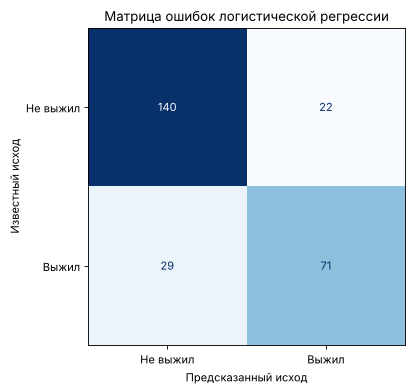

In [14]:
cm = confusion_matrix(y_test, y_pred_logreg, labels=CLASS_IDS)
assert cm.sum() == len(y_test)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set(xlabel='Предсказанный исход', ylabel='Известный исход',
       title='Матрица ошибок логистической регрессии')
plt.tight_layout()
plt.show()


Ответ: в матрице 140 и 71 верных ответов на диагонали, 22 и 29 ошибок вне её. Всего 140 + 22 + 29 + 71 = 262, это все строки теста.

Клетка «Не выжил / Выжил» (22): модель назвала выжившими 22 пассажира, которые на самом деле погибли. Это ложные срабатывания, из-за них precision 0.763.

Клетка «Выжил / Не выжил» (29): модель пропустила 29 выживших из 100, сказала про них «не выжил». Отсюда recall 0.71. Пропусков выживших больше, чем ложных срабатываний, модель чаще ошибается в сторону «не выжил».

Вместо галереи изображений здесь разбираем **строки таблицы**.
Присоедините ответы к `X_test`, выделите несовпадения и покажите первые
шесть. Исходные индексы сохранены; предсказания идут в порядке строк теста.
Их нельзя сопоставлять с первыми строками исходного `df`.

Какие значения были пропущены? Какие записи выглядят похожими, но имеют
разные исходы? По одной строке можно предложить объяснение ошибки,
но нельзя установить её причину.


In [15]:
test_predictions = X_test.copy()
test_predictions['Известный исход'] = y_test.to_numpy()
test_predictions['Предсказанный исход'] = y_pred_logreg
mistakes = test_predictions[test_predictions['Известный исход']
                            != test_predictions['Предсказанный исход']]  # строки с разными известным и предсказанным исходами
print('Ошибок логистической регрессии:', len(mistakes))
display(mistakes.head(6))
display(mistakes.groupby(['Известный исход', 'Предсказанный исход'])
        .size().rename('Ошибок').to_frame())


Ошибок логистической регрессии: 51


,age,fare,sibsp,parch,pclass,sex,embarked,Известный исход,Предсказанный исход
1028,NaN,24.1500,1,0,3,female,Q,1,0
1121,NaN,22.3583,1,1,3,male,C,1,0
20,37.0,52.5542,1,1,1,male,S,1,0
975,26.0,16.1000,1,0,3,female,S,0,1
742,45.0,8.0500,0,0,3,male,S,1,0
889,26.0,7.7750,0,0,3,male,S,1,0


,,Ошибок
Известный исход,Предсказанный исход,
0,1,22
1,0,29


Ответ: у логистической регрессии 51 ошибка: 29 пропущенных выживших и 22 ложных «выжил». Пропуски среди этих строк только в возрасте, он неизвестен у 10 из 51. В первых шести ошибках возраста нет у двух пассажиров (строки 1028 и 1121), модель подставила им медиану 28 лет.

Похожие записи с разными исходами тоже есть. Строки 889 и 742: мужчины третьего класса из Саутгемптона, едут одни, билет около 8 фунтов. Оба выжили, а модель ответила «не выжил». Во всём наборе таких мужчин от 20 до 30 лет 114, и выжили из них только 18. Модель выбрала то, что для этой группы бывает чаще.

Строки 975 и 1028: обе женщины из третьего класса, у обеих на борту один брат, сестра или супруг, билет от 16 до 24 фунтов. Первая погибла, хотя модель сказала «выжил». Вторая выжила, хотя модель сказала «не выжил». Среди женщин третьего класса в наборе выжила примерно половина (49%), и по семи признакам их не различить. Можно предположить, что исход решало то, чего в таблице нет, например где человек был во время эвакуации. Но по одной строке это только догадка, причину ошибки так не установить.

## 9. Одна запись для модели

Возьмите первую строку `X_test`. `iloc[[0]]` сохраняет форму таблицы:
одна строка, семь столбцов. Получите класс и две оценки вероятности
с помощью `logreg`. Сохраните названия столбцов и их смысл.

Затем сравните с известным ответом. Это демонстрация на строке из того
же теста, а не дополнительная независимая проверка. Высокая вероятность
не гарантирует правильного ответа и не объясняет причину исхода.


In [16]:
new_passenger = X_test.iloc[[0]].copy()
new_prediction = logreg.predict(new_passenger)  # predict
new_probabilities = logreg.predict_proba(new_passenger)  # predict_proba
display(new_passenger)
print('Ответ модели:', CLASS_NAMES[int(new_prediction[0])])
print('Известный исход:', CLASS_NAMES[int(y_test.iloc[0])])
display(pd.DataFrame(new_probabilities, columns=CLASS_NAMES).round(3))


,age,fare,sibsp,parch,pclass,sex,embarked
1028,NaN,24.15,1,0,3,female,Q


Ответ модели: Не выжил
Известный исход: Выжил


,Не выжил,Выжил
0,0.514,0.486


Ответ: первая строка теста это пассажирка третьего класса, села на борт в Куинстауне, возраст неизвестен, билет 24.15 фунта, на борту один брат, сестра или супруг. Модель ответила «не выжил» с вероятностью 0.514, а «выжил» получил 0.486. На самом деле пассажирка выжила, то есть модель ошиблась (это та же строка 1028 из таблицы ошибок). Вероятности почти поровну, модель здесь по сути не уверена: небольшой сдвиг в признаках поменял бы ответ. Высокая вероятность тоже не гарантировала бы верный ответ, она показывает только, насколько строка похожа на учебные случаи с тем же исходом.

## 10. Вывод

Запишите 3–4 предложения по своим результатам:

1. Какие признаки получила модель и что она предсказывала?
2. Как обработали пропуски и категории? Почему подготовку обучали после разделения?
3. Насколько модели превзошли простой ориентир? Какие ошибки видно по матрице?
4. Почему эти оценки не доказывают качество для другого рейса или другой группы людей?

Случайное разделение- упрощение этой работы. Родственники и пассажиры
с общим билетом могут попасть в разные части и иметь связанные исходы.
Для отдельного исследования можно разделять по группам билетов.
Наблюдаемая связь признака с исходом сама по себе не доказывает причину.


**Мой вывод**

Модели получили семь признаков пассажира: возраст, стоимость проезда, число братьев, сестёр и супругов, число родителей и детей, класс билета, пол и порт посадки. По ним они предсказывали, выжил пассажир (1) или нет (0).

Пропуски в числах заменили медианой, в категориях самым частым значением. Категории превратили в отдельные столбцы-индикаторы через `OneHotEncoder`, числа привели к одному масштабу (кроме дерева). Всё это обучалось только на `X_train`. Если бы медиану и масштаб считали по всему набору, в них попали бы сведения о тесте, и оценка получилась бы завышенной.

Ориентир дал accuracy 0.618. У KNN 0.794, у логистической регрессии 0.805, у дерева 0.836, KNN обогнал ориентир на 17.6 процентного пункта, дерево на 21.8. По матрице ошибок видно, что логистическая регрессия чаще пропускает выживших (29 из 100), чем ошибочно называет выжившими погибших (22 из 162).

Эти оценки получены на 262 пассажирах одного рейса. Сильнее всего с исходом здесь связаны пол, класс билета и возраст до 12 лет, и связь эта зависит от того, как шла эвакуация именно на «Титанике». На другом судне или у другой группы людей связь может быть другой. К тому же случайное разделение разносит родственников и попутчиков по одному билету в обучение и тест, а их исходы связаны, поэтому тест здесь не совсем независимый.


## Дополнительно: число соседей

Для тех, кто закончил раньше, или для домашней работы.
Сравните `k=3, 5, 9, 15` с пятичастной перекрёстной проверкой **внутри
X_train**. В каждом проходе заново обучаются и подготовка, и модель.
Сравниваем F1 для класса 1. Покажите среднее и стандартное отклонение.

Разброс по проходам не является доверительным интервалом. Не подбирайте
параметры по общему тесту: он уже использован для основной проверки.
Для итоговой оценки модели, выбранной после просмотра теста, нужна
ещё одна независимая проверка.


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for k in [3, 5, 9, 15]:
    candidate = Pipeline([
        ('prep', clone(preprocessor)),
        ('model', KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring='f1')  # cross_val_score: candidate, X_train, y_train, cv=cv, scoring='f1'
    cv_rows.append({'k': k, 'Среднее F1': scores.mean(), 'Разброс (std)': scores.std()})
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(3))


,k,Среднее F1,Разброс (std)
0,3,0.695,0.020
1,5,0.716,0.027
2,9,0.682,0.014
3,15,0.702,0.016


Ответ: лучшее среднее F1 при `k=5`, 0.716. Дальше идут `k=15` (0.702), `k=3` (0.695) и `k=9` (0.682). Разброс по проходам от 0.014 до 0.027, и разница между соседними `k` с ним сравнима. Поэтому уверенно сказать, что `k=5` лучше `k=15`, нельзя. Пять соседей из основной работы выглядят разумным выбором, и подобрали мы это внутри `X_train`, тест для этого не трогали.

## Справка и источник данных

- [Titanic, OpenML, data_id=40945](https://www.openml.org/d/40945).
  CSV получен через `sklearn.datasets.fetch_openml(data_id=40945, as_frame=True)`.
  В нём сохранены все 1309 строк, исходные признаки и пропуски;
  `survived` записан целыми числами.
- [Пример scikit-learn с числовыми и категориальными признаками Titanic](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html).
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html),
  [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html),
  [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- [Подготовка данных и утечка информации](https://scikit-learn.org/stable/common_pitfalls.html).
- [Метрики классификации](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
